In [ ]:
import numpy as np
import matplotlib.pyplot as plt
!pip install hmmlearn
from scipy.stats import linregress
from sklearn.preprocessing import StandardScaler
from hmmlearn.hmm import GaussianHMM




[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
np.random.seed(444)

n = 300

# Phase 0: stable low-noise
phase0 = np.random.normal(
    loc=0,
    scale=0.3,
    size=n
)

# Phase 1: increasing trend
phase1 = (
    np.linspace(0, 5, n)
    + np.random.normal(
        0,
        0.25,
        n
    )
)

# Phase 2: high-variance regime
phase2 = np.random.normal(
    loc=8,
    scale=1.5,
    size=n
)

signal = np.concatenate([
    phase0,
    phase1,
    phase2
])

true_boundaries = [300, 600]

In [ ]:
def build_features(signal, window=30):

    means = []
    stds = []
    slopes = []

    for i in range(len(signal)):

        start = max(0, i - window + 1)

        x = signal[start:i + 1]

        means.append(np.mean(x))
        stds.append(np.std(x))

        if len(x) > 2:
            slope = linregress(
                np.arange(len(x)),
                x
            ).slope
        else:
            slope = 0

        slopes.append(slope)

    return np.column_stack([
        means,
        stds,
        slopes
    ])


features = build_features(
    signal,
    window=30
)

scaler = StandardScaler()

X = scaler.fit_transform(
    features
)

# For RWD

# def autocorr(x, lag=1):
#     if len(x) <= lag:
#         return 0

#     x1 = x[:-lag]
#     x2 = x[lag:]

#     if np.std(x1) == 0 or np.std(x2) == 0:
#         return 0

#     return np.corrcoef(x1, x2)[0, 1]


# def build_features(signal, window=30):

#     means = []
#     stds = []
#     slopes = []
#     ranges = []
#     autocorrs = []
#     skews = []
#     kurtoses = []

#     for i in range(len(signal)):

#         start = max(0, i - window + 1)
#         x = signal[start:i + 1]

#         means.append(np.mean(x))
#         stds.append(np.std(x))

#         ranges.append(np.max(x) - np.min(x))

#         autocorrs.append(
#             autocorr(x, lag=1)
#         )

#         if len(x) > 3:
#             skews.append(skew(x))
#             kurtoses.append(kurtosis(x))
#         else:
#             skews.append(0)
#             kurtoses.append(0)

#         if len(x) > 2:
#             slope = linregress(
#                 np.arange(len(x)),
#                 x
#             ).slope
#         else:
#             slope = 0

#         slopes.append(slope)

#     return np.column_stack([
#         means,
#         stds,
#         slopes,
#         ranges,
#         autocorrs,
#         skews,
#         kurtoses
#     ])

In [ ]:
model = GaussianHMM(
    n_components=3,
    covariance_type="full",
    n_iter=500,
    random_state=42
)

model.fit(X)

# set number of states for clean phase detection

states = model.predict(X)

state_probs = model.predict_proba(X)


def extract_intervals(states):

    intervals = []

    start = 0
    current = states[0]

    for i in range(1, len(states)):

        if states[i] != current:

            intervals.append(
                (
                    int(current),
                    start,
                    i - 1
                )
            )

            start = i
            current = states[i]

    intervals.append(
        (
            int(current),
            start,
            len(states) - 1
        )
    )

    return intervals


intervals = extract_intervals(states)

print("\nDetected intervals:\n")

for state, start, end in intervals:

    print(
        f"State {state}: "
        f"{start} -> {end} "
        f"(length={end-start+1})"
    )


Detected intervals:

State 1: 0 -> 16 (length=17)
State 0: 17 -> 368 (length=352)
State 1: 369 -> 378 (length=10)
State 0: 379 -> 599 (length=221)
State 1: 600 -> 624 (length=25)
State 2: 625 -> 899 (length=275)



State statistics:

State 0
  Mean = 1.295
  Std  = 1.666
  Count= 573

State 1
  Mean = 4.016
  Std  = 3.847
  Count= 52

State 2
  Mean = 7.934
  Std  = 1.512
  Count= 275



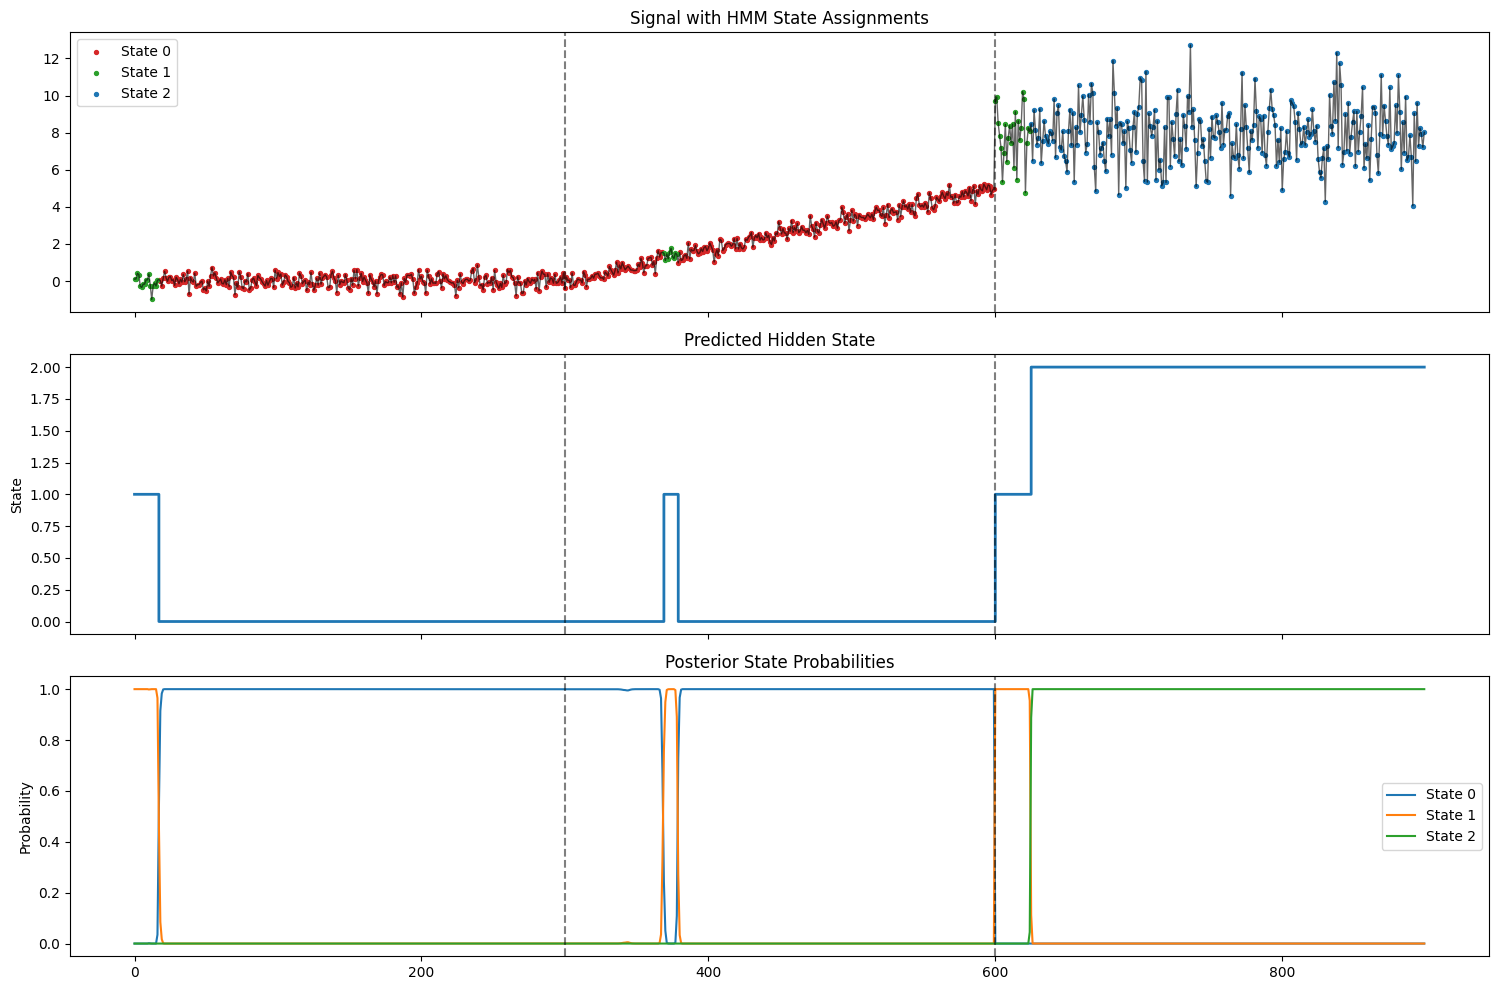

In [7]:
print("\nState statistics:\n")

for state in np.unique(states):

    vals = signal[states == state]

    print(
        f"State {state}"
    )

    print(
        f"  Mean = {vals.mean():.3f}"
    )

    print(
        f"  Std  = {vals.std():.3f}"
    )

    print(
        f"  Count= {len(vals)}"
    )

    print()


fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 10),
    sharex=True
)

colors = [
    "tab:red",
    "tab:green",
    "tab:blue",
    "tab:orange",
    "tab:purple"
]

# ----------------------------------------------------------
# Plot 1: Raw signal + state assignments
# ----------------------------------------------------------

axes[0].plot(
    signal,
    color="black",
    alpha=0.6,
    linewidth=1
)

for state in np.unique(states):

    idx = states == state

    axes[0].scatter(
        np.where(idx)[0],
        signal[idx],
        s=8,
        color=colors[state],
        label=f"State {state}"
    )

for boundary in true_boundaries:
    axes[0].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[0].set_title(
    "Signal with HMM State Assignments"
)

axes[0].legend()


# ----------------------------------------------------------
# Plot 2: State sequence
# ----------------------------------------------------------

axes[1].plot(
    states,
    drawstyle="steps-post",
    linewidth=2
)

for boundary in true_boundaries:
    axes[1].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[1].set_title(
    "Predicted Hidden State"
)

axes[1].set_ylabel(
    "State"
)


# ----------------------------------------------------------
# Plot 3: State probabilities
# ----------------------------------------------------------

for state in range(model.n_components):

    axes[2].plot(
        state_probs[:, state],
        label=f"State {state}"
    )

for boundary in true_boundaries:
    axes[2].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[2].set_title(
    "Posterior State Probabilities"
)

axes[2].set_ylabel(
    "Probability"
)

axes[2].legend()


plt.tight_layout()
plt.show()